# submesoscale heat flux comparison: with wind VS turn off the wind

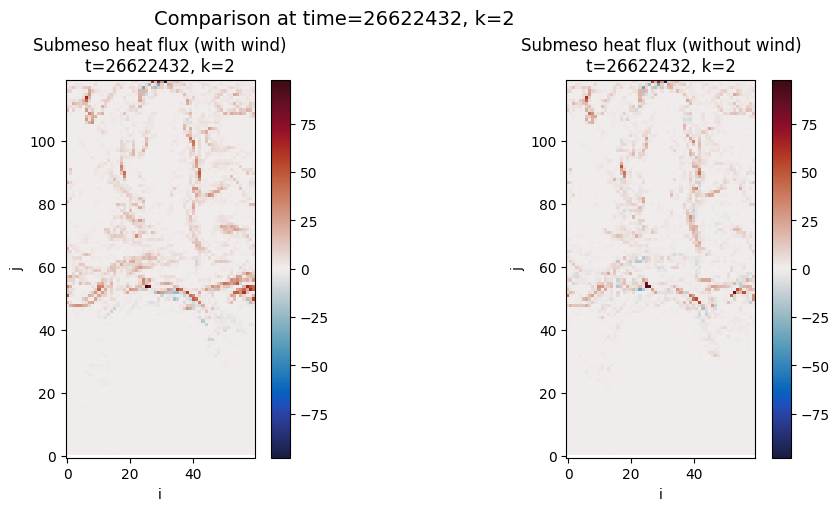

In [7]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean

# -----------------------------
# parameters
# -----------------------------
k_idx = 2
t_val = 26622432  # time point

# -----------------------------
# load data
# -----------------------------
path_scratch = '/scratch/jczhang/'
path_data = 'submeso_data_driven/src/post_analysis/test_wind_submeso_field/'
sub = "with_wind.nc"
sub_o = "without_wind.nc"

submeso_heat_flux = xr.open_dataset(path_scratch + path_data + sub, engine="h5netcdf")
submeso_heat_flux_o = xr.open_dataset(path_scratch + path_data + sub_o, engine="h5netcdf")

# -----------------------------
# variable name
# -----------------------------
sub_var = "wT_sub_kC"

# -----------------------------
# extract 2D slices at given time and k
# -----------------------------
da_with = submeso_heat_flux[sub_var].sel(time=t_val).isel(k=k_idx)
da_without = submeso_heat_flux_o[sub_var].sel(time=t_val).isel(k=k_idx)

# -----------------------------
# symmetric color limits
# -----------------------------
vmax = np.nanmax(np.abs(da_with.values))
vmax = max(vmax, np.nanmax(np.abs(da_without.values)))
vmin, vmax = -vmax, vmax

# -----------------------------
# plot: two panels side by side
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)

im0 = axes[0].imshow(da_with.values, origin="lower", cmap=cmocean.cm.balance, vmin=vmin, vmax=vmax)
axes[0].set_title(f"Submeso heat flux (with wind)\nt={t_val}, k={k_idx}")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
axes[0].set_xlabel("i")
axes[0].set_ylabel("j")

im1 = axes[1].imshow(da_without.values, origin="lower", cmap=cmocean.cm.balance, vmin=vmin, vmax=vmax)
axes[1].set_title(f"Submeso heat flux (without wind)\nt={t_val}, k={k_idx}")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
axes[1].set_xlabel("i")
axes[1].set_ylabel("j")

plt.suptitle(f"Comparison at time={t_val}, k={k_idx}", fontsize=14)
plt.show()